##READ DATA

In [ ]:
import os
import random
import cv2
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import drive
from PIL import Image

from skimage.feature import graycomatrix, graycoprops

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

In [ ]:
drive.mount('/content/drive')
train_pneumonia_dir = '/content/drive/MyDrive/TA/Dataset/train/PNEUMONIA'
test_pneumonia_dir = '/content/drive/MyDrive/TA/Dataset/test/PNEUMONIA'
train_normal_dir = '/content/drive/MyDrive/TA/Dataset/train/NORMAL'
test_normal_dir = '/content/drive/MyDrive/TA/Dataset/test/NORMAL'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def get_all_files(dirs, allowed_extensions=['.jpg', '.jpeg', '.png']):
    all_files = []
    for dir_path in dirs:
        files = [os.path.join(dir_path, f) for f in os.listdir(dir_path)
                 if not f.startswith('.') and os.path.splitext(f)[1].lower() in allowed_extensions]
        all_files.extend(files)
    return all_files

def random_select_files(file_list, subset_size):
    if subset_size > len(file_list):
        raise ValueError("Jumlah file yang diminta lebih besar daripada jumlah file yang tersedia.")
    return random.sample(file_list, subset_size)

def count_files(directory):
  return len(os.listdir(directory))

##BALANCING

In [ ]:
all_pneumonia_files = get_all_files([train_pneumonia_dir, test_pneumonia_dir])
all_normal_files = get_all_files([train_normal_dir, test_normal_dir])

print(f"train pneumon : {count_files(train_pneumonia_dir)}")
print(f"test pneumon : {count_files(test_pneumonia_dir)}")
print(f"train norm : {count_files(train_normal_dir)}")
print(f"test norm : {count_files(test_normal_dir)}")

print(f"pneumon : {len(all_pneumonia_files)}")
print(f"norm : {len(all_normal_files)}")


train pneumon : 3875
test pneumon : 390
train norm : 1341
test norm : 234
pneumon : 4265
norm : 1575


oversampling

In [ ]:
# train_pneumonia_count = 3200
# test_pneumonia_count = 1065
# train_normal_count = 3200
# test_normal_count = 1065

# test_pneumonia_samples = random.sample(all_pneumonia_files, test_pneumonia_count)
# test_normal_samples = random.sample(all_normal_files, test_normal_count)

# pneumonia_train_pool = [f for f in all_pneumonia_files if f not in test_pneumonia_samples]
# normal_train_pool = [f for f in all_normal_files if f not in test_normal_samples]

# train_pneumonia_samples = random.choices(pneumonia_train_pool, k=train_pneumonia_count)
# train_normal_samples = random.choices(normal_train_pool, k=train_normal_count)

undersampling

In [ ]:
train_pneumonia_samples = random_select_files(all_pneumonia_files, 1181)
test_pneumonia_samples = random_select_files([f for f in all_pneumonia_files if f not in train_pneumonia_samples], 394)

train_normal_samples = random_select_files(all_normal_files, 1181)
test_normal_samples = random_select_files([f for f in all_normal_files if f not in train_normal_samples], 394)

In [ ]:
print(f"train_pneumonia_samples : {len(train_pneumonia_samples)}")
print(f"test_pneumonia_samples : {len(test_pneumonia_samples)}")
print(f"train_normal_samples : {len(train_normal_samples)}")
print(f"test_normal_samples : {len(test_normal_samples)}")

train_pneumonia_samples : 1181
test_pneumonia_samples : 394
train_normal_samples : 1181
test_normal_samples : 394


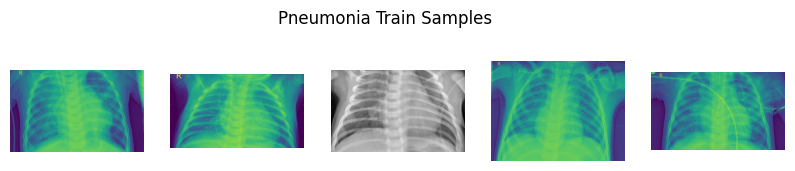

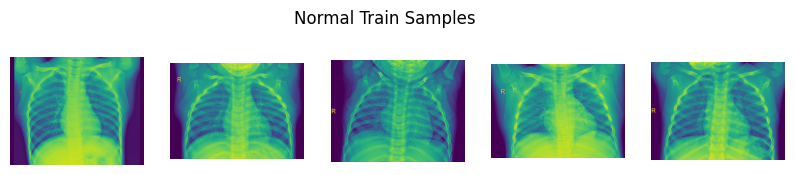

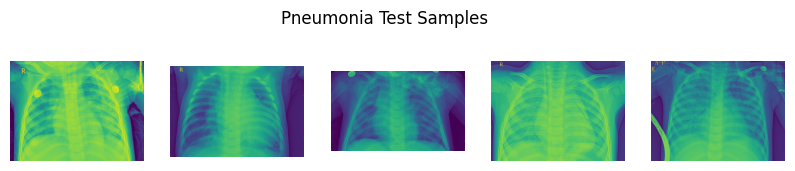

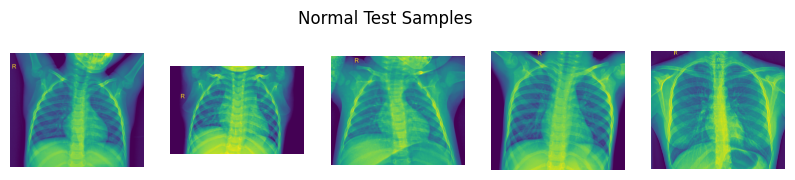

In [ ]:
def show_sample_images(sample_files,ammount, title):
    fig = plt.figure(figsize=(10, 2.5))
    plt.suptitle(title, y=0.9)
    for i in range(ammount):
        plt.subplot(1, ammount, i+1)
        img = Image.open(sample_files[i])
        plt.imshow(img)
        plt.axis('off')
    plt.show()

show_sample_images(train_pneumonia_samples, 5, 'Pneumonia Train Samples')
show_sample_images(train_normal_samples, 5, 'Normal Train Samples')
show_sample_images(test_pneumonia_samples, 5, 'Pneumonia Test Samples')
show_sample_images(test_normal_samples, 5, 'Normal Test Samples')

##RESIZE

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def load_images(file_paths, target_size=(224, 224)):
    images = []
    for i, file_path in enumerate(file_paths):
        img = load_img(file_path, target_size=target_size)
        img_array = img_to_array(img)
        img_array = img_array - 30
        img_array = img_array / 255.0
        images.append(img_array)
    return images

train_pneumonia_images = load_images(train_pneumonia_samples)
test_pneumonia_images = load_images(test_pneumonia_samples)
train_normal_images = load_images(train_normal_samples)
test_normal_images = load_images(test_normal_samples)

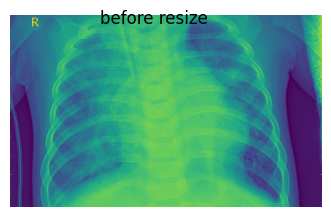

Text(0.5, 1.0, 'After Resizing')

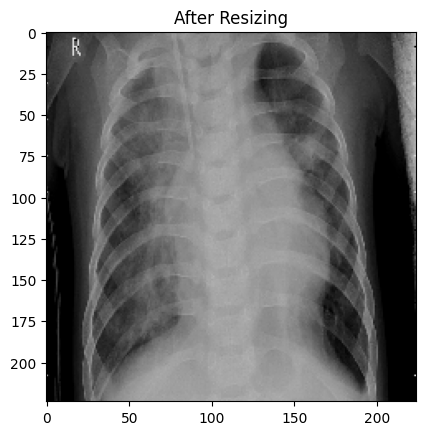

In [ ]:
show_sample_images(train_pneumonia_samples, 1, 'before resize')
plt.imshow(train_pneumonia_images[0])
plt.title('After Resizing')

##GLCM

In [ ]:
def calculate_glcm(image):
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    distances = [1, 2, 3]
    angles = [0, np.pi/4, np.pi/2, 3*np.pi/4]

    glcm = graycomatrix(gray_image,
                        distances=distances,
                        angles=angles,
                        levels=256,
                        symmetric=True,
                        normed=True)

    properties = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    features = {}

    for prop in properties:
        values = graycoprops(glcm, prop).flatten()
        features[f'{prop}_mean'] = np.mean(values)
        features[f'{prop}_std'] = np.std(values)
        features[f'{prop}_var'] = np.var(values)

    glcm_entropy = -np.sum(glcm * np.log2(glcm + 1e-10))
    features['entropy'] = glcm_entropy

    return features


In [ ]:
def extract_glcm_features(image_list):
    glcm_features_list = []
    for image in image_list:
        image_uint8 = (image * 255).astype(np.uint8)
        features = calculate_glcm(image_uint8)
        glcm_features_list.append(features)
    return glcm_features_list

train_pneumonia_glcm = extract_glcm_features(train_pneumonia_images)
test_pneumonia_glcm = extract_glcm_features(test_pneumonia_images)
train_normal_glcm = extract_glcm_features(train_normal_images)
test_normal_glcm = extract_glcm_features(test_normal_images)

print("GLCM features for the first pneumonia training image:")
train_pneumonia_glcm[0]


GLCM features for the first pneumonia training image:


{'contrast_mean': np.float64(1002.9710768133938),
 'contrast_std': np.float64(497.0806712422826),
 'contrast_var': np.float64(247089.19372267826),
 'dissimilarity_mean': np.float64(11.141508669511268),
 'dissimilarity_std': np.float64(3.8098231165009246),
 'dissimilarity_var': np.float64(14.51475217902482),
 'homogeneity_mean': np.float64(0.20123310468688682),
 'homogeneity_std': np.float64(0.044979719990052354),
 'homogeneity_var': np.float64(0.002023175210383515),
 'energy_mean': np.float64(0.022192629279966087),
 'energy_std': np.float64(0.002864901896434685),
 'energy_var': np.float64(8.207662876195055e-06),
 'correlation_mean': np.float64(0.8480956610105799),
 'correlation_std': np.float64(0.0764052113163412),
 'correlation_var': np.float64(0.005837756316294755),
 'ASM_mean': np.float64(0.0005007204572342033),
 'ASM_std': np.float64(0.000130337257642022),
 'ASM_var': np.float64(1.6987800729642825e-08),
 'entropy': np.float64(147.71585679944494)}

In [ ]:
#import pandas as pd
#from google.colab import files

#train_pneumonia_df = pd.DataFrame(train_pneumonia_glcm)
#train_pneumonia_df['label'] = 'PNEUMONIA'

#test_pneumonia_df = pd.DataFrame(test_pneumonia_glcm)
#test_pneumonia_df['label'] = 'PNEUMONIA'

#train_normal_df = pd.DataFrame(train_normal_glcm)
#train_normal_df['label'] = 'NORMAL'

#test_normal_df = pd.DataFrame(test_normal_glcm)
#test_normal_df['label'] = 'NORMAL'

#all_glcm_df = pd.concat([train_pneumonia_df, test_pneumonia_df, train_normal_df, test_normal_df], ignore_index=True)

#excel_filename = 'glcm_features.xlsx'
#all_glcm_df.to_excel(excel_filename, index=False)

#files.download(excel_filename)

#print(f"GLCM features saved to '{excel_filename}' and downloaded.")

##ANN

In [ ]:
# GLCM - DF
train_pneumonia_glcm_df = pd.DataFrame(train_pneumonia_glcm)
test_pneumonia_glcm_df = pd.DataFrame(test_pneumonia_glcm)
train_normal_glcm_df = pd.DataFrame(train_normal_glcm)
test_normal_glcm_df = pd.DataFrame(test_normal_glcm)

train_pneumonia_glcm_df['label'] = 1  # 1 for pneumonia
test_pneumonia_glcm_df['label'] = 1
train_normal_glcm_df['label'] = 0  # 0 for normal
test_normal_glcm_df['label'] = 0

train_glcm_df = pd.concat([train_pneumonia_glcm_df, train_normal_glcm_df], ignore_index=True)
test_glcm_df = pd.concat([test_pneumonia_glcm_df, test_normal_glcm_df], ignore_index=True)


# Separate features
X_train = train_glcm_df.drop('label', axis=1)
y_train = train_glcm_df['label']
X_test = test_glcm_df.drop('label', axis=1)
y_test = test_glcm_df['label']

# Normal
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Model
model = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.0001), input_shape=(X_train.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu', kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu', kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

optimizer = Adam(learning_rate=0.001)
class_weights = {0: 1.5, 1: 0.8}

callbacks = [
    EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=25, min_lr=1e-6)
]

model.compile(optimizer=optimizer,
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.AUC()])

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.3,
    callbacks=None,
    class_weight=class_weights,
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,825 (54.00 KB)

 Trainable params: 13,377 (52.25 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6721 - auc: 0.7572 - loss: 0.6834 - val_accuracy: 0.8251 - val_auc: 0.0000e+00 - val_loss: 0.5849
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8022 - auc: 0.8884 - loss: 0.4722 - val_accuracy: 0.8265 - val_auc: 0.0000e+00 - val_loss: 0.5394
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8282 - auc: 0.8985 - loss: 0.4419 - val_accuracy: 0.8547 - val_auc: 0.0000e+00 - val_loss: 0.5140
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8451 - auc: 0.9191 - loss: 0.3879 - val_accuracy: 0.8674 - val_auc: 0.0000e+00 - val_loss: 0.4679
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8548 - auc: 0.9197 - loss: 0.3810 - val_accuracy: 0.8674 - val_auc: 0.0000e+00 - val_loss: 0.4468
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8651 - auc: 0.9260 - loss: 0.3687 - val_accuracy: 0.8815 - val_auc: 0.0000e+00 - val_loss: 0.3961
Epoch 7/50
52/52 ━━━━━━━━━━

In [ ]:
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)
test_loss, test_accuracy, test_auc = model.evaluate(X_test, y_test, verbose=0)
test_precision = precision_score(y_test, y_pred_classes)
test_recall = recall_score(y_test, y_pred_classes)

print(f"- Loss: {test_loss:.4f}")
print(f"- AUC: {test_auc:.4f}")
print(f"- Accuracy: {test_accuracy:.4f}")

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
- Loss: 0.2691
- AUC: 0.9605
- Accuracy: 0.9036


In [ ]:
print(classification_report(y_test, y_pred_classes))


              precision    recall  f1-score   support

           0       0.91      0.90      0.90       394
           1       0.90      0.91      0.90       394

    accuracy                           0.90       788
   macro avg       0.90      0.90      0.90       788
weighted avg       0.90      0.90      0.90       788



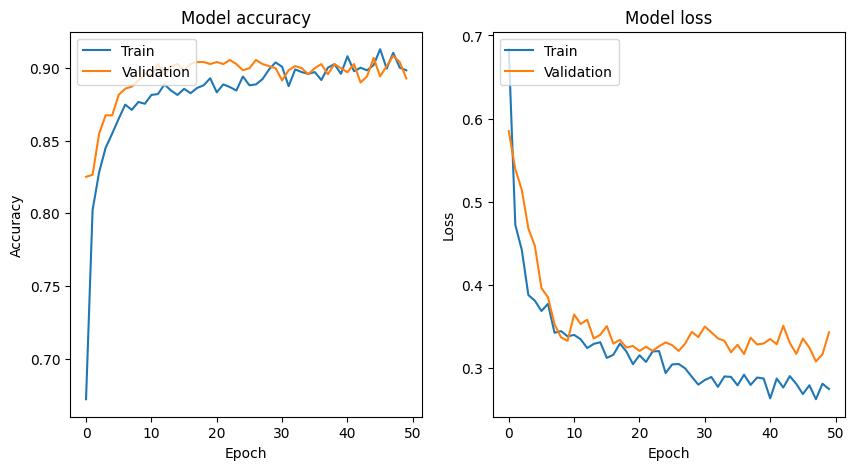

In [ ]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.show()

##PREDICT

In [ ]:
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


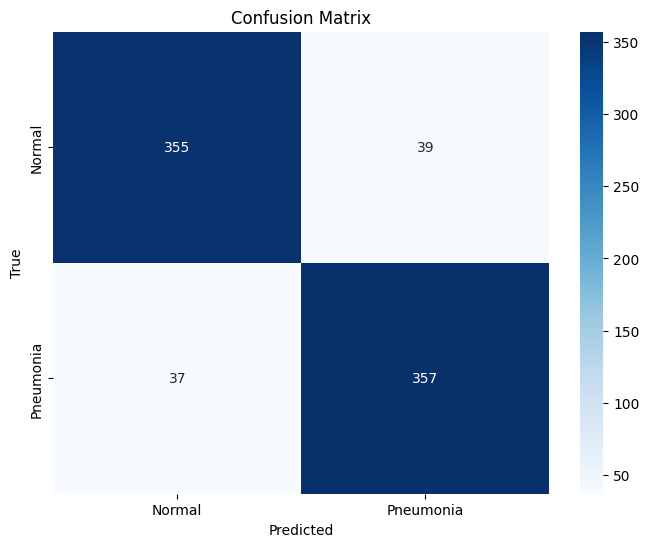

In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


--------------------------------------------------------------------------------

--------------------------------------------------------------------------------

CODE END HERE

In [ ]:
from google.colab import files

In [ ]:
model.save("Pnem_sim.h5")

In [ ]:
files.download("Pnem_sim.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

In [ ]:
files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>